In [1]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

# rsync -av --progress login.nird.sigma2.no:/projects/NS9600K/data/Met-No_obs/  /uio/kant/geo-metos-u1/franzihe/Documents/input/Met-No_obs

In [2]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]


if "mimi" in hostname:
    DATA_DIR = "/scratch/franzihe/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"

elif "augustiner" in hostname: 
    DATA_DIR = "/home/franzihe/Data/"
    FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

elif "wessel" in hostname:
    DATA_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

wessel.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt,radar, np, DateFormatter, datetime, cm, pd)


In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
# plt.rc('font', size=21) #controls default text size
# plt.rcParams["font.serif"]= ['DejaVu Serif']


In [6]:
sites = ["ANX", "ALOMAR"]
years = ["2021", "2022"]

In [7]:
mrr_in_dict = {}
ds_dict = {}
met_no_dict = {}
ds_dict_metno = {}
for site in sites:
    for year in years:
        mrr_in_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'MRR_islas/maahn/*{}*{}*'.format(site, year))))
        met_no_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*{}*'.format(year))))
        try:
            ds_dict['{}.{}'.format(site, year)] = xr.open_mfdataset(mrr_in_dict['{}.{}'.format(site, year)], decode_times=True, )
            ds_dict_metno['{}.{}'.format(site, year)] = xr.open_mfdataset(met_no_dict['{}.{}'.format(site, year)], decode_times=True, )
            print("Reading files for {} in {}".format(site, year))
        except OSError:
            ds_dict['{}.{}'.format(site, year)] = xr.Dataset()
            ds_dict_metno['{}.{}'.format(site, year)] = xr.Dataset()
            # print("No files to open for {} in {}".format(site, year))
            continue

Reading files for ANX in 2021
Reading files for ANX in 2022


In [8]:
# key = "ANX.2022"
title = ['MRR reflectivity', 'MRR mean Doppler Velocity', '2-m Air temperature', 'Precipitation', '10-m Wind']

ValueError: hour must not be empty

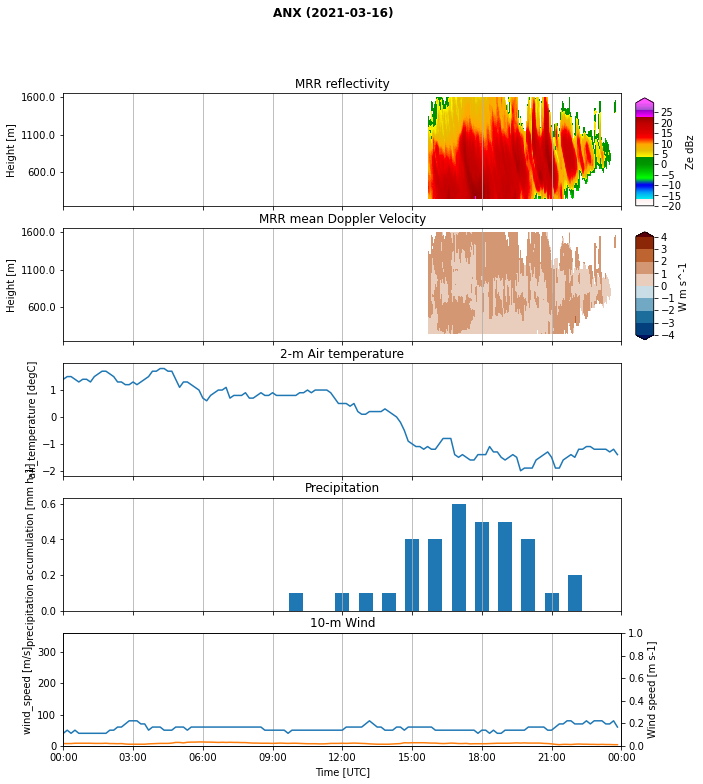

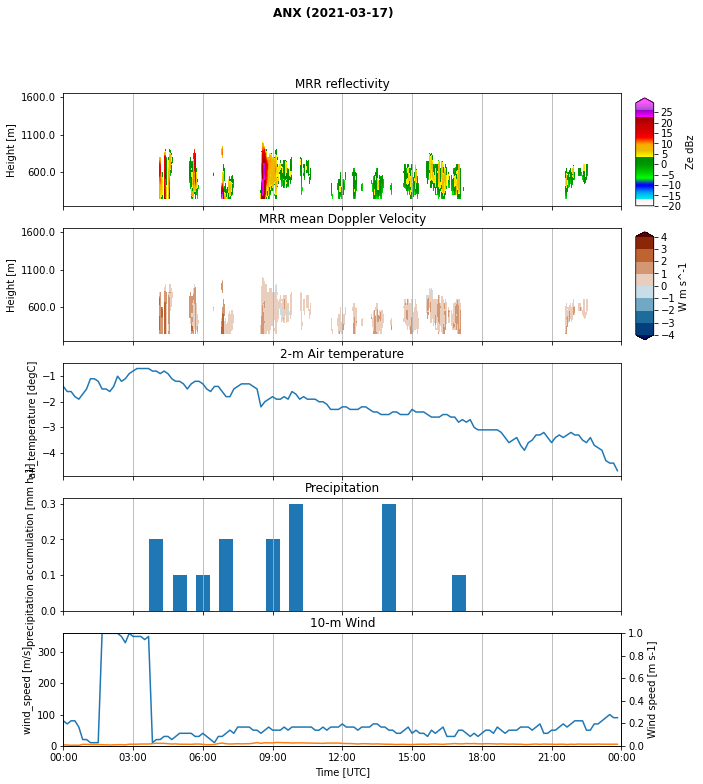

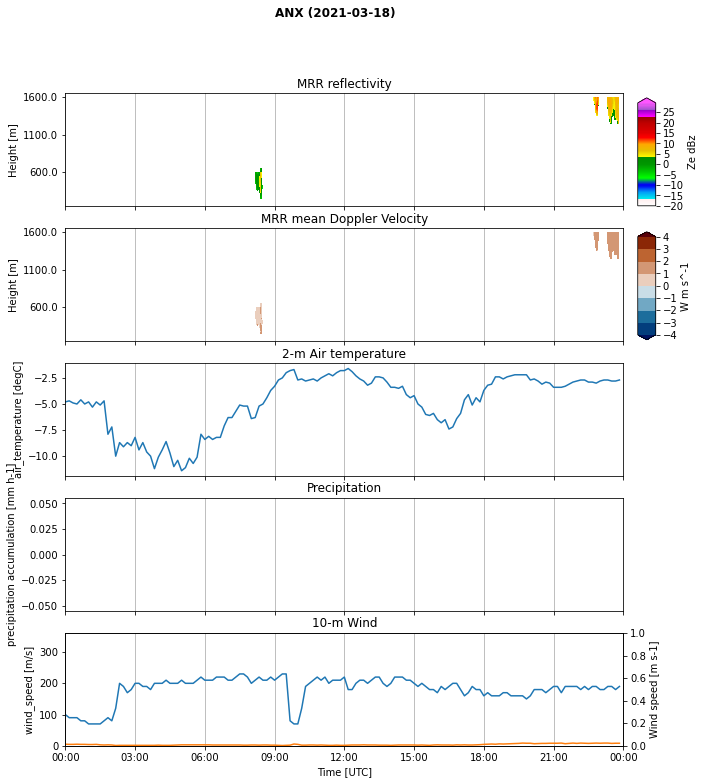

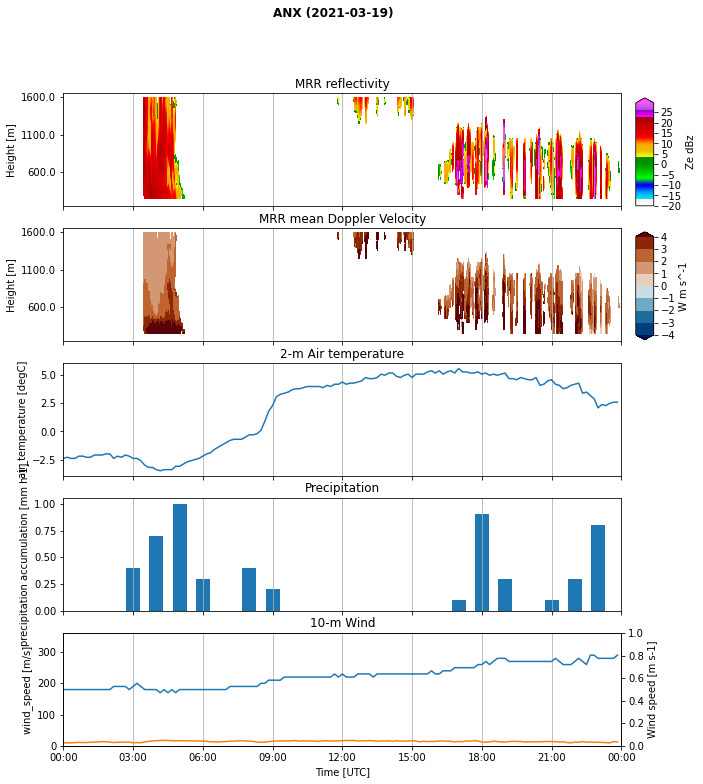

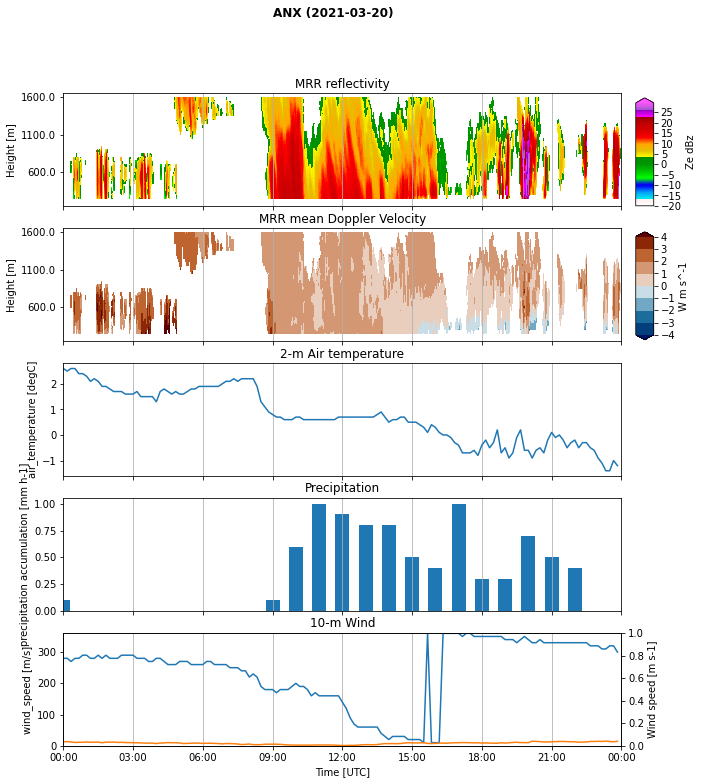

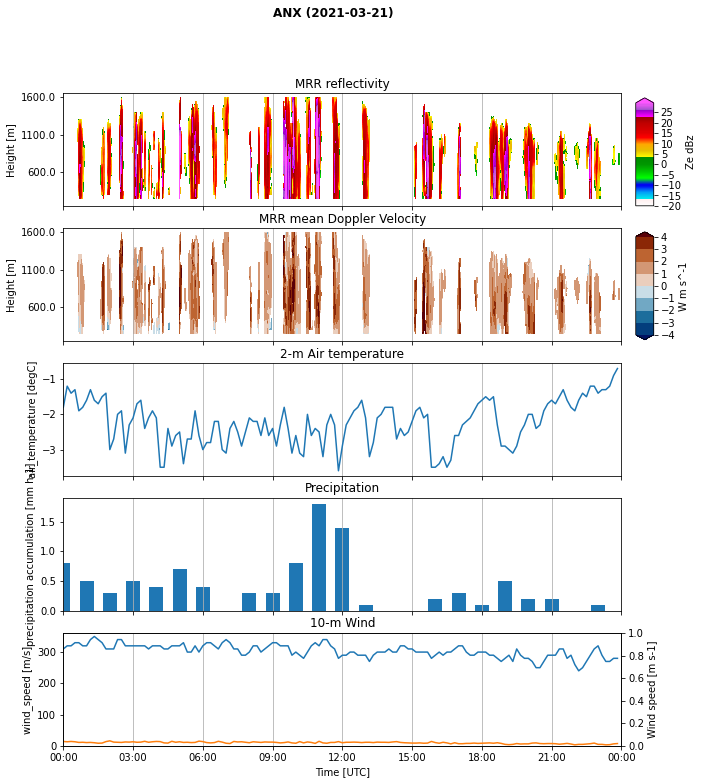

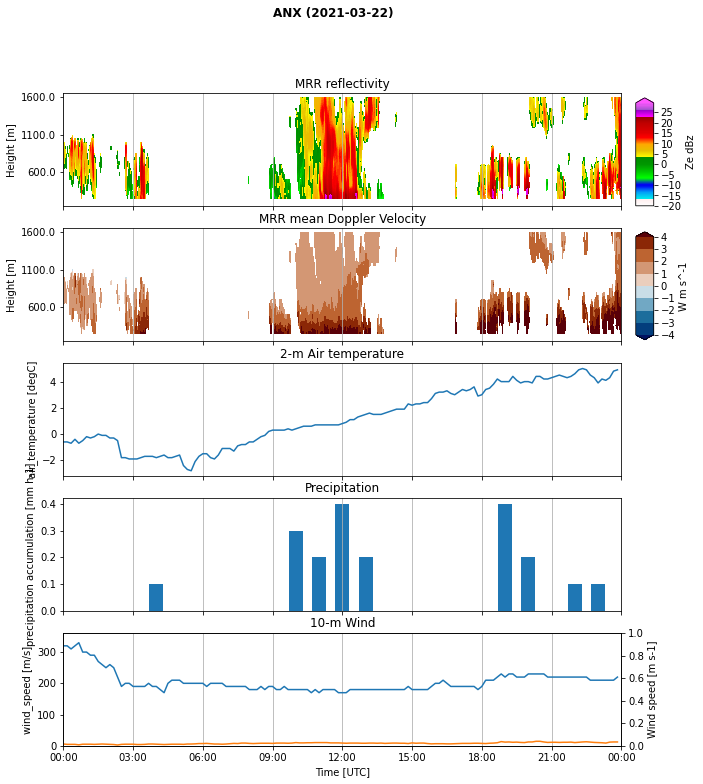

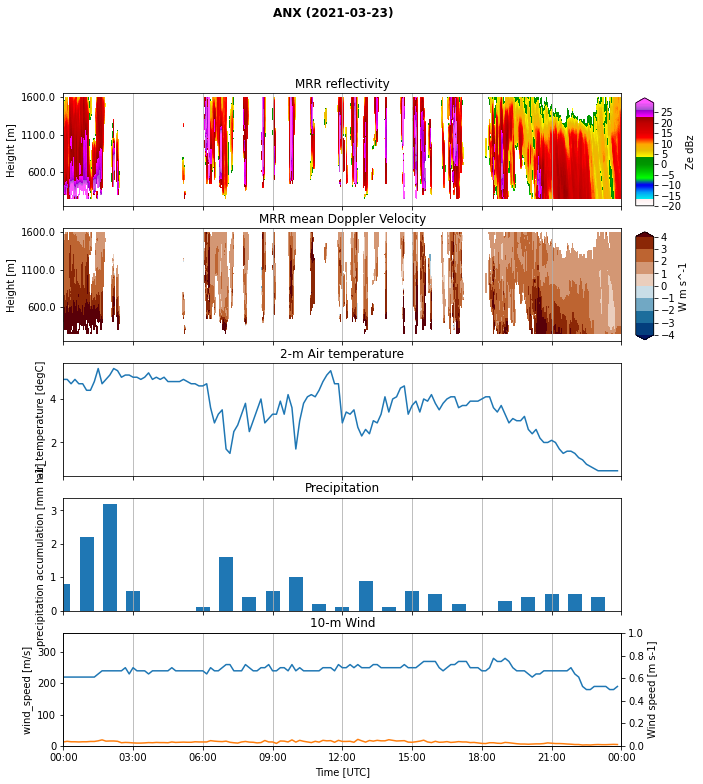

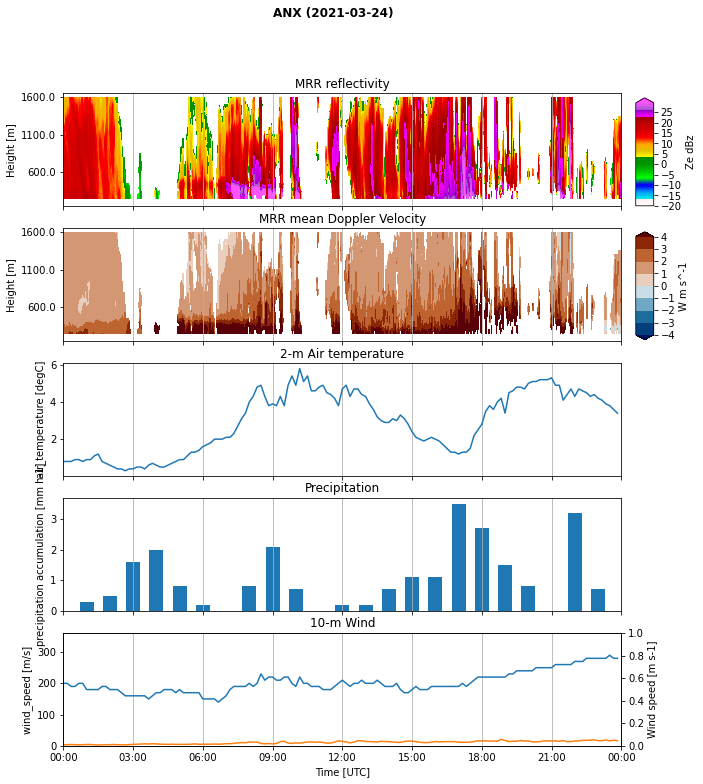

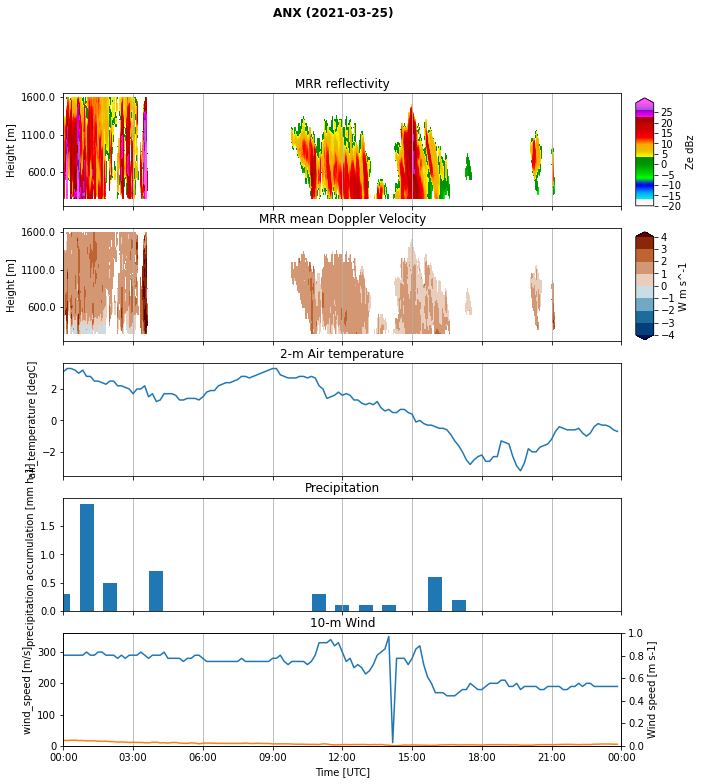

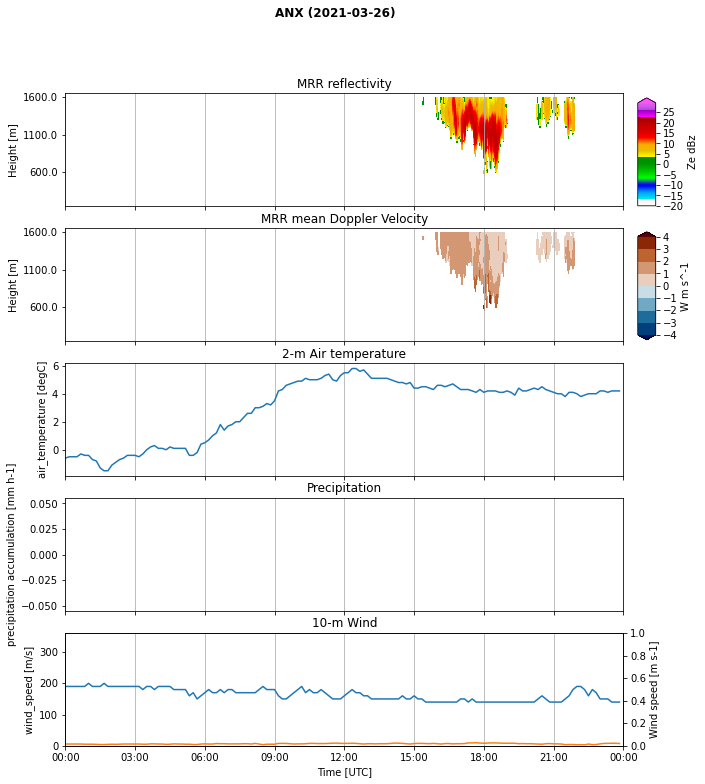

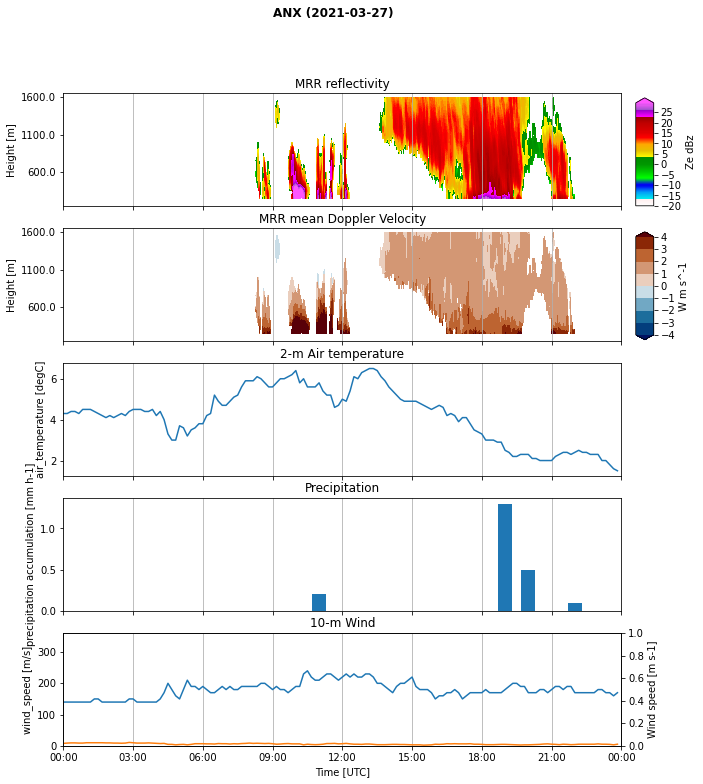

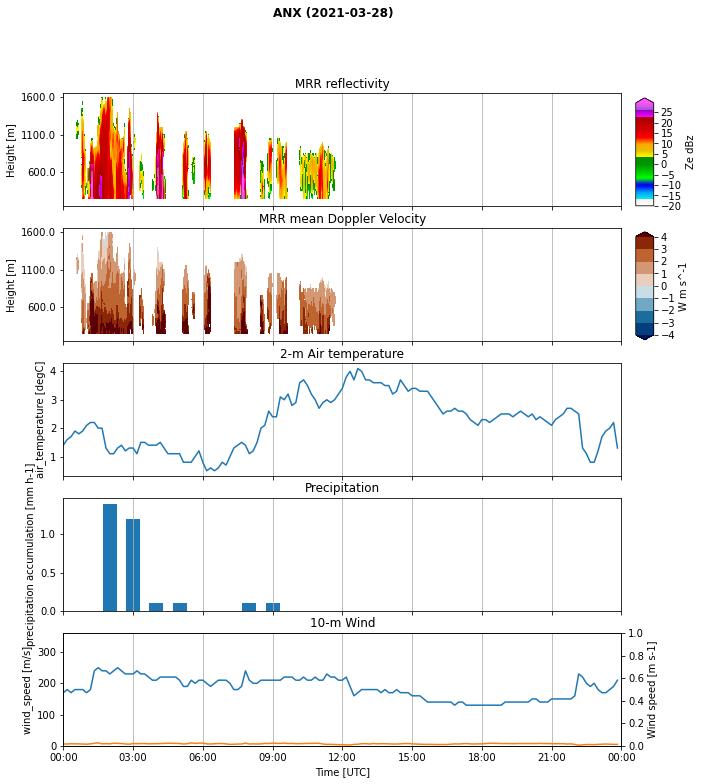

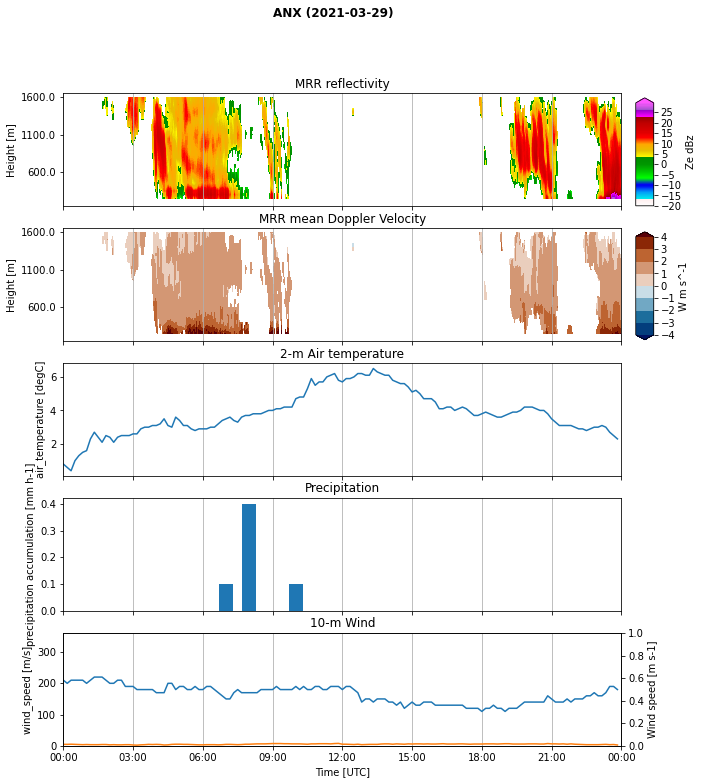

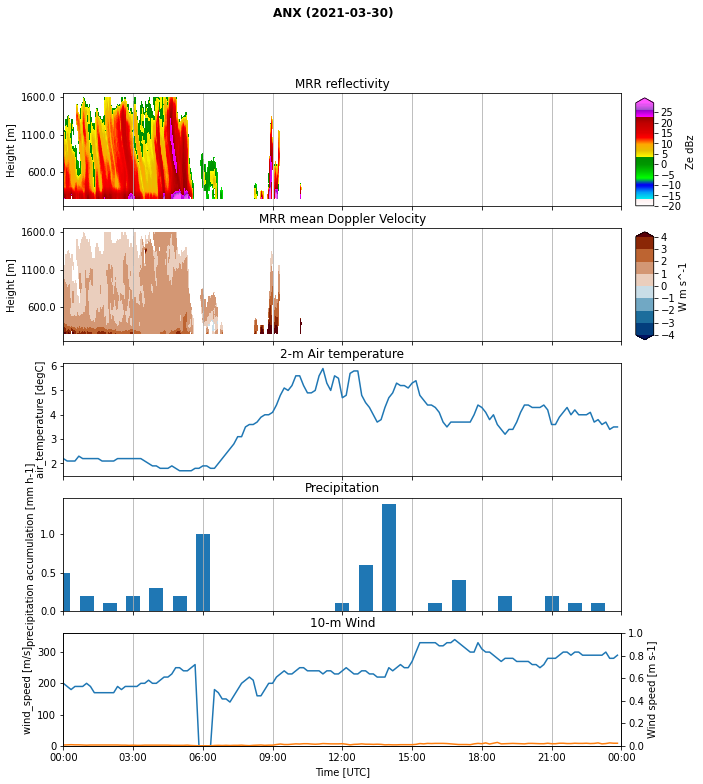

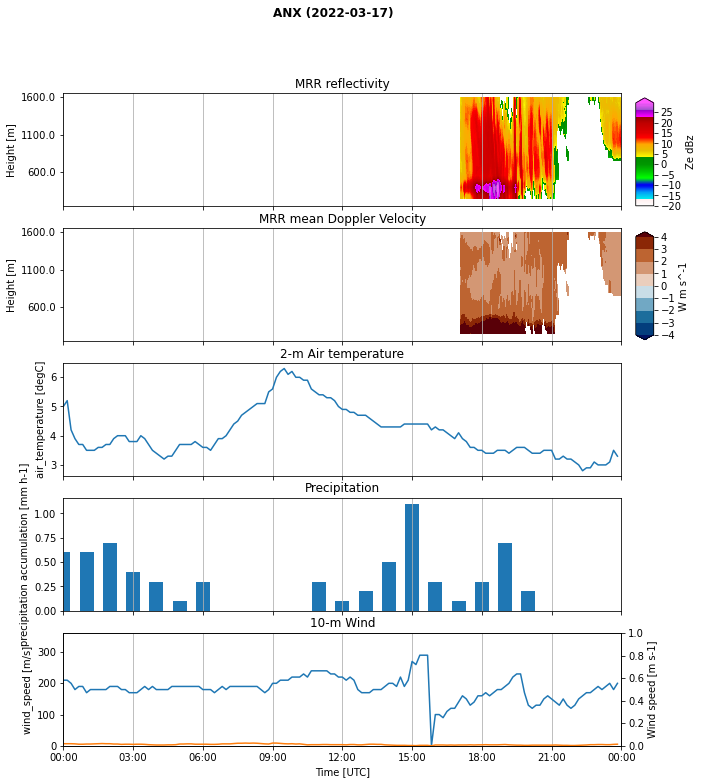

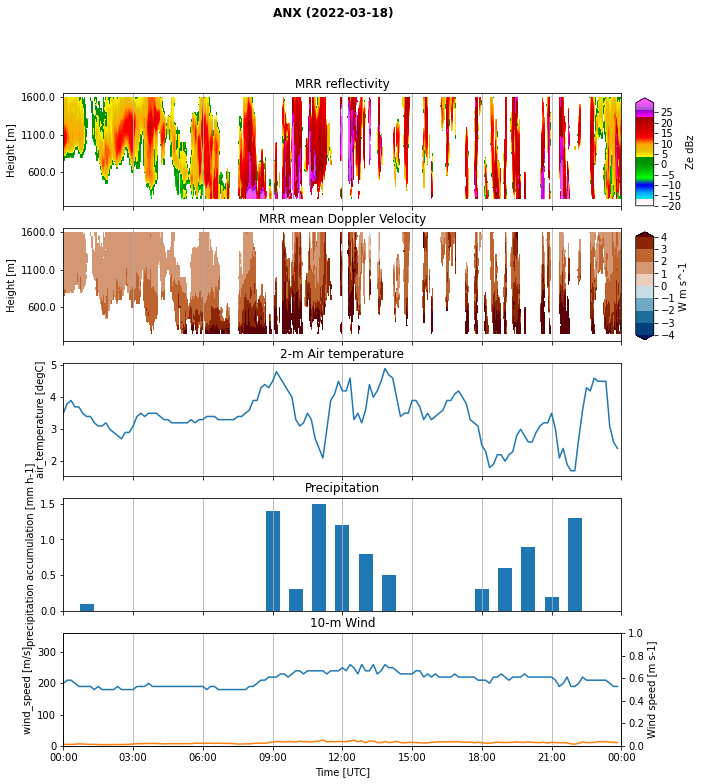

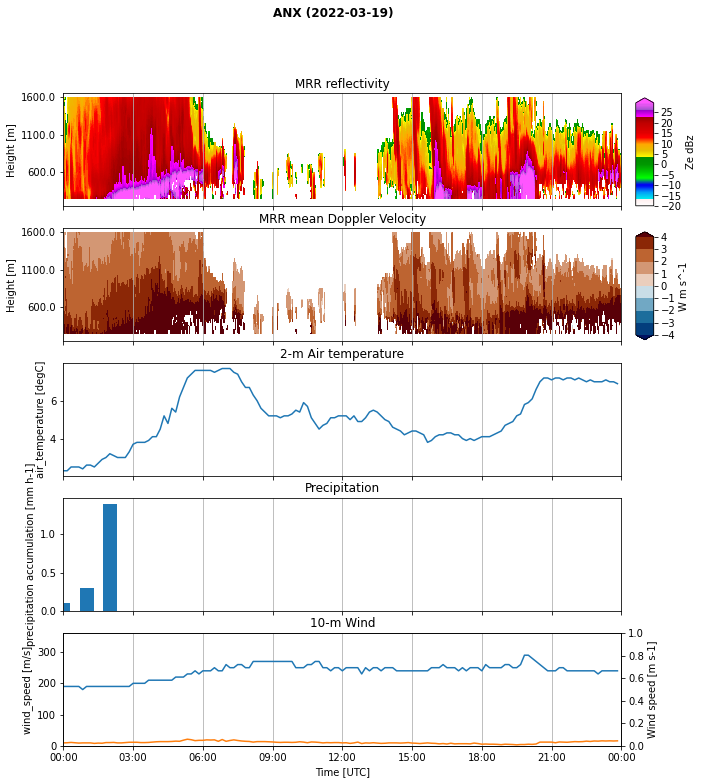

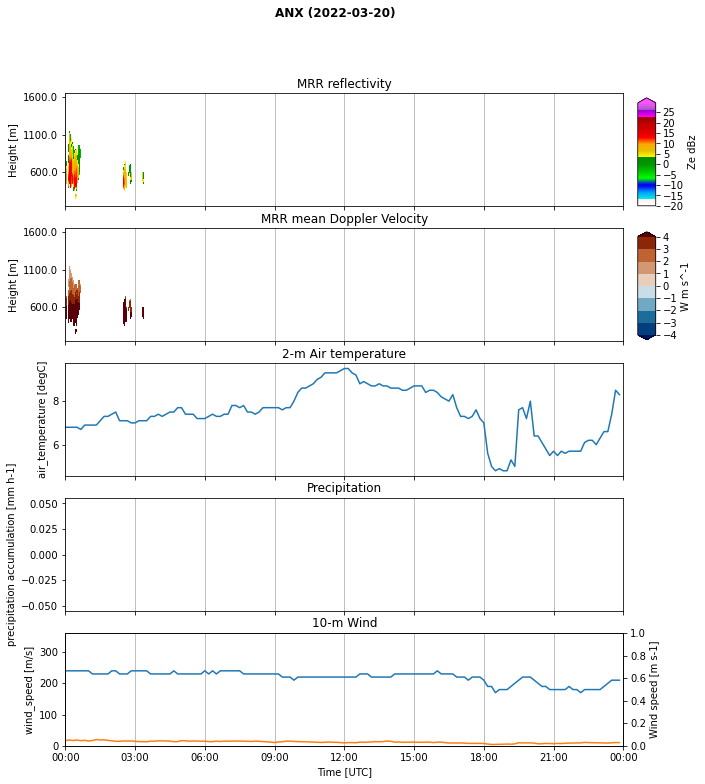

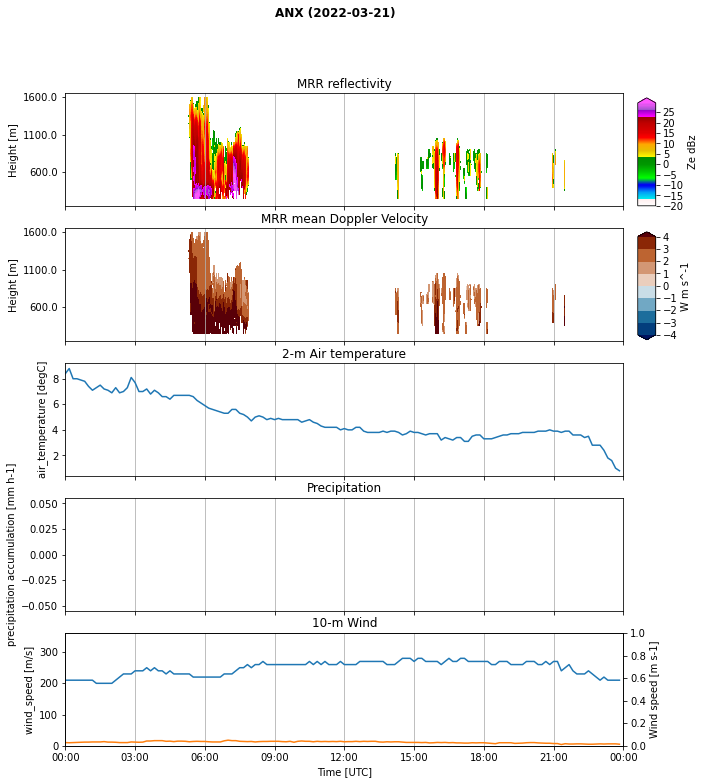

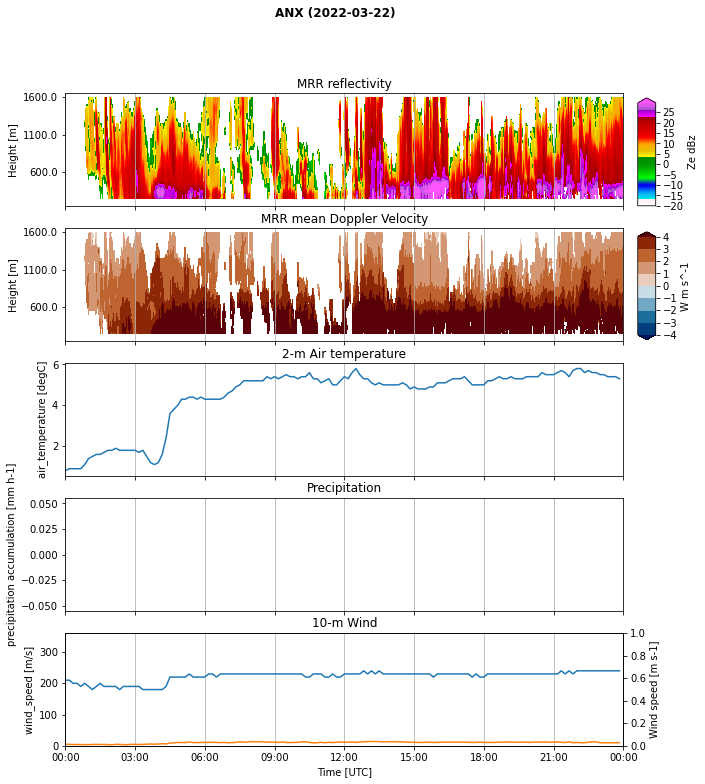

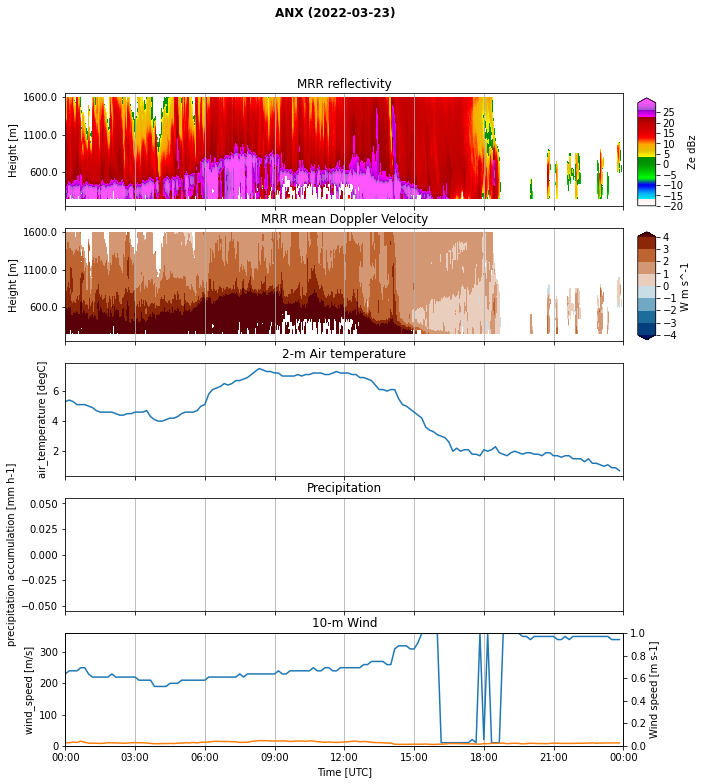

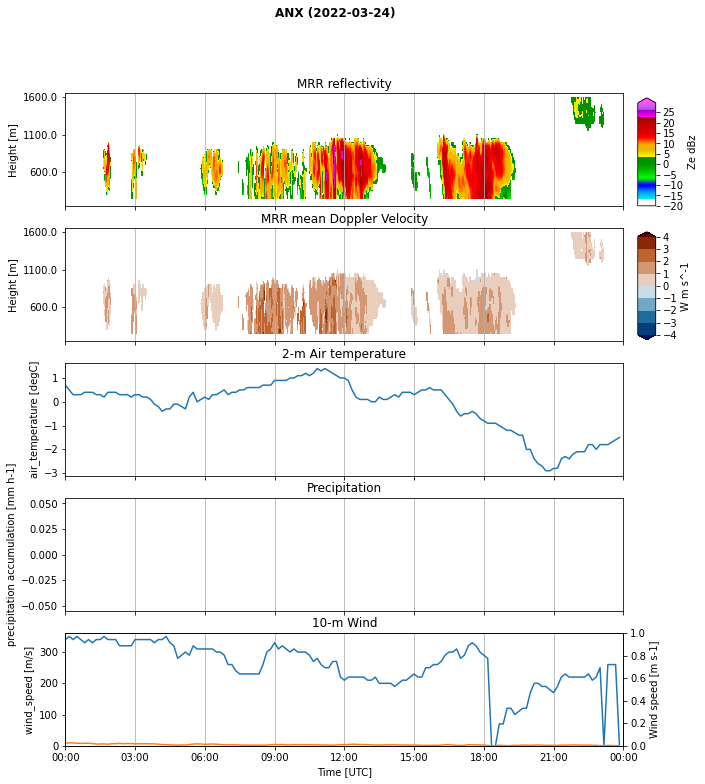

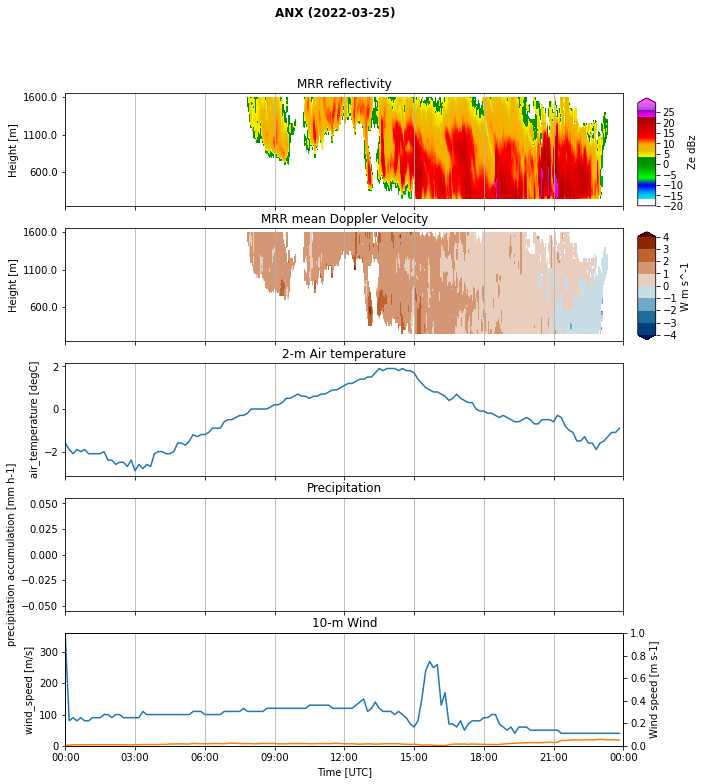

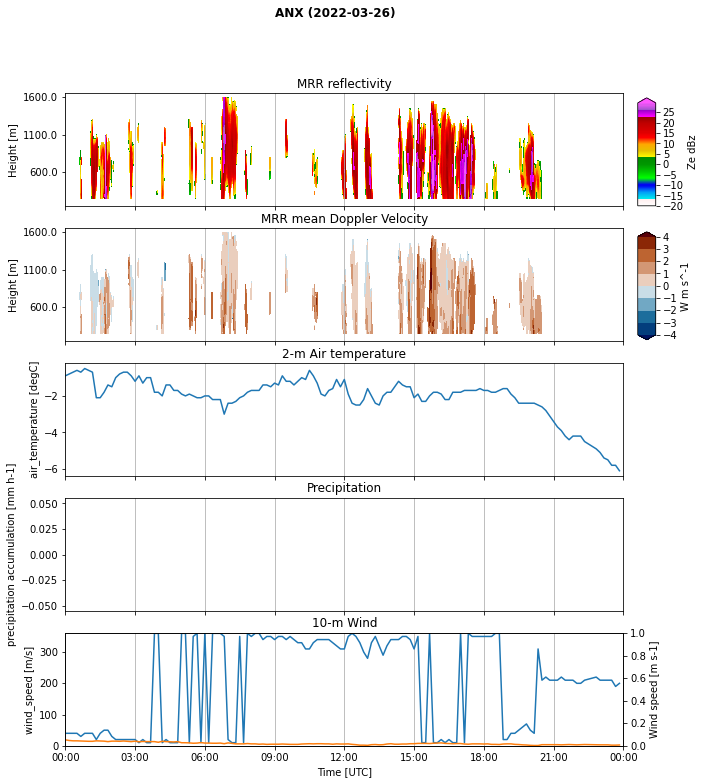

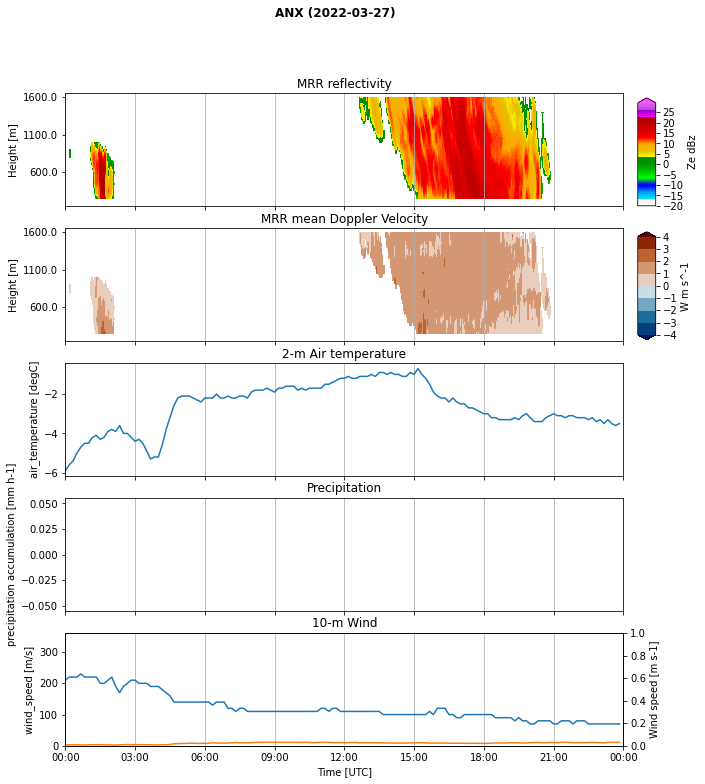

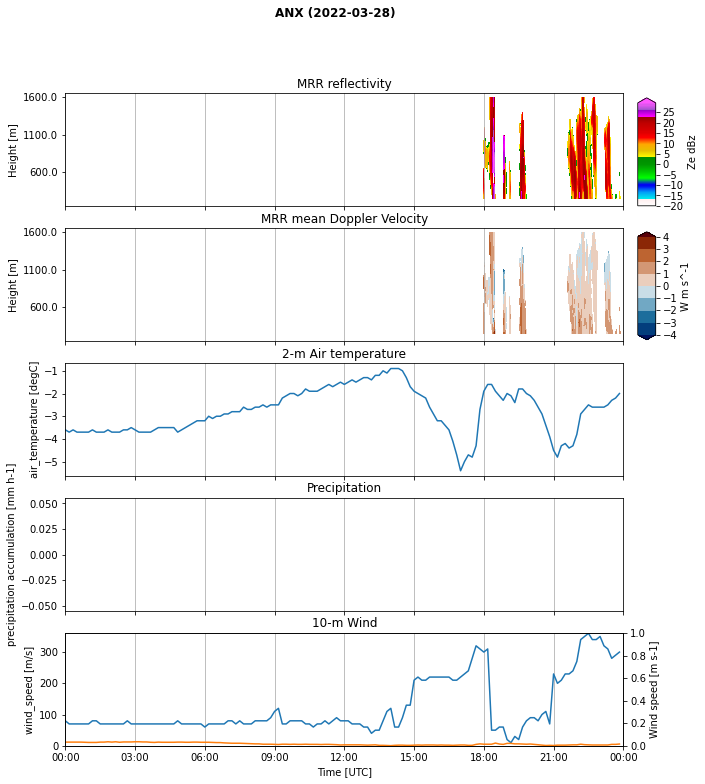

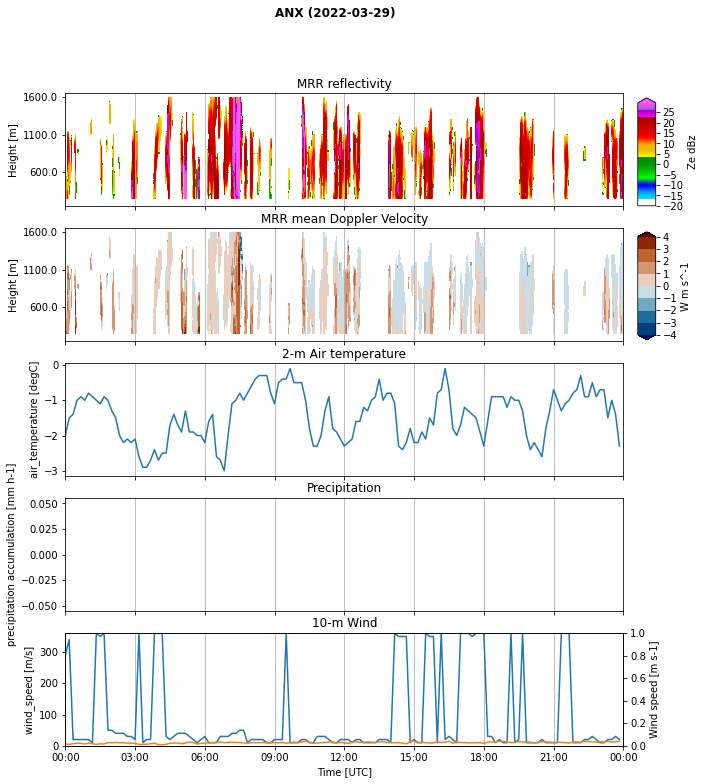

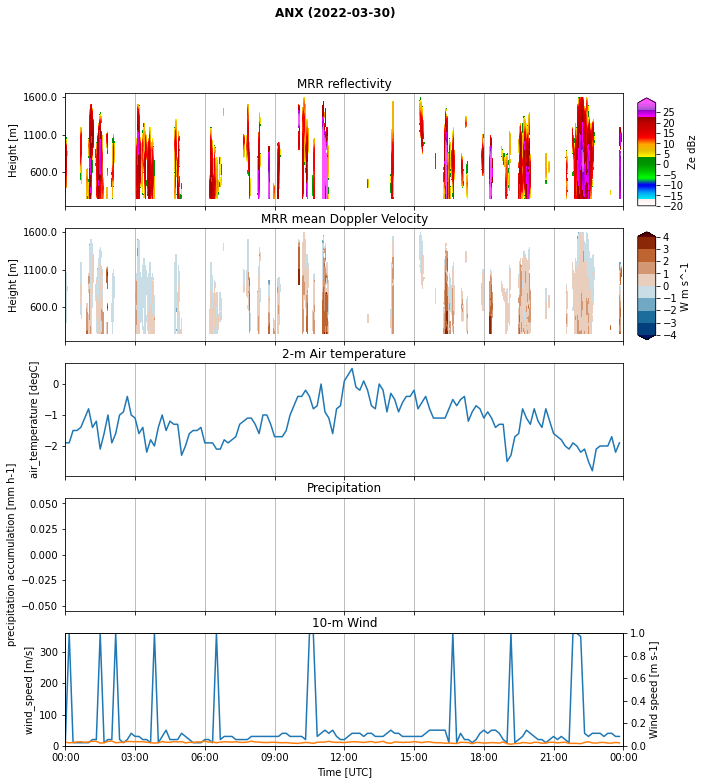

In [10]:
for key in mrr_in_dict.keys():
    # print(len(mrr_in_dict[key]))
    

    for j in range(len(mrr_in_dict[key])):
        
        date = mrr_in_dict[key][j][-11:-3]
        
        # Define name for figure
        figname = 'mrr_reflectivity_{}_{}'.format(key.split('.')[0], date)
        
        # Define start and end time of individual day
        day_start = datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S').strftime('%Y-%m-%d %H:%M:%S')
        day_end = (datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S') + datetime.timedelta(hours=23, minutes=59)).strftime('%Y-%m-%d %H:%M:%S')

        # select reflectivity and height to make radar reflectivity plot
        _Ze = ds_dict[key]['Ze'].sel(time = slice(day_start, day_end))
        _height = ds_dict[key]['height'].sel(time = slice(day_start, day_end))
        
        # select mean doppler veleocity
        _W = ds_dict[key]['W'].sel(time = slice(day_start, day_end))

        _air_temp = ds_dict_metno[key]['air_temperature'].sel(time = slice(day_start, day_end))
        _pp = ds_dict_metno[key]['sum(precipitation_amount PT1H)'].sel(time = slice(day_start, day_end)).groupby('time.hour').sum('time')
        _wd = ds_dict_metno[key]['wind_from_direction'].sel(time = slice(day_start, day_end))
        _ws = ds_dict_metno[key]['wind_speed'].sel(time = slice(day_start, day_end))


        _sometime = []
        for hours in _pp.hour.values:
                _sometime.append((datetime.datetime.strptime("{} 00:00:00".format(date), '%Y%m%d %H:%M:%S') + datetime.timedelta(hours=int(hours))).strftime('%Y-%m-%d %H:%M:%S'))


        _pp = _pp.assign_coords({'hour': _sometime}).rename(hour='time')
        _pp['time'] = pd.DatetimeIndex(_pp['time'].values)

        

        fig, axsm = plt.subplots(5, 1, figsize=[10,12], sharex=True, )
        axs = axsm.flatten()

        p1 = _Ze.plot.contourf(ax = axs[0], x='time', y='range', vmin = -20, 
                            levels = np.arange(-20, 30,0.5), 
                            cmap=plt.get_cmap('pymeteo_radar'), extend='max', add_colorbar=False,)
        cbaxes = fig.add_axes([0.92, 0.75, 0.025, 0.125])
        cbar = plt.colorbar(p1, cax=cbaxes, shrink=0.5, orientation='vertical')
        cbar.ax.set_ylabel('Ze {}'.format(_Ze.attrs['units']))

        
        p2 = _W.plot.contourf(ax = axs[1], x='time', y='range',vmin=-4, vmax=4, 
                         levels=np.arange(-4,4.5), extend='both', cmap=cm.vik, add_colorbar=False,)
        cbaxes = fig.add_axes([0.92, 0.595, 0.025, 0.125])
        cbar = plt.colorbar(p2, cax=cbaxes, shrink=0.5, orientation='vertical')
        cbar.ax.set_ylabel('W {}'.format(_W.attrs['units']))

        _air_temp.plot(ax = axs[2], x='time')
        # _pp.plot(ax=axs[3], x='time')#.to_series().plot.bar(ax = axs[3], x='time')
        axs[3].bar(_pp['time'].values, _pp.values, width=0.025, align='center')

        par1 = axs[4].twinx()
        _wd.plot(ax=axs[4], x='time')
        _ws.plot(ax=axs[4], x='time')
        
        _xmax = (datetime.datetime.strptime(day_end, '%Y-%m-%d %H:%M:%S') + datetime.timedelta(minutes=1,)).strftime('%Y-%m-%d %H:%M:%S')
        # Define the date format
        date_form = DateFormatter("%H:00")
        for ax, tt in zip(axs,title):
            ax.set( xlabel = "",
                    title =tt)
            ax.xaxis.grid()
            ax.set_xlim([day_start, _xmax])
            ax.tick_params(axis='x', labelrotation=0, )
            plt.setp(ax.get_xticklabels(), horizontalalignment="center")
            ax.xaxis.set_major_formatter(date_form)
        for ax in axs[0:2]:
                ax.set(ylabel = "Height [m]", yticklabels=_height.isel(time=0).values[::5])
        axs[3].set_ylabel('precipitation accumulation [mm h-1]')
        
        axs[4].set_ylim(0, 360)
        # par1.set_ylim(0, 5)
        par1.set_ylabel('Wind speed [m s-1]')

        axs[-1].set(xlabel = "Time [UTC]",)
            
        fig.suptitle("{} ({})".format(key.split('.')[0], _Ze.time.dt.date[0].values), fontweight="bold");
        
        # plt.tight_layout()
        # fig.subplots_adjust(top=0.25)
        
        # save image to png
        plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True)
        


In [ ]:
# rsync -a --progress /home/franzihe/Documents/Figures/mrr_reflectivity notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/u6030275/public_html/Figures

In [ ]:
# rsync -a --progress login.nird.sigma2.no:/projects/NS9600K/sldam/timelapses_islas2022 /home/franzihe/Documents/Figures